# Project: Air Quality Forecasting in India

**Research question:** How accurately can machine learning models predict tomorrow's average PM2.5 concentration in Indian cities using air-quality information available today, and do they outperform the simple baseline that predicts tomorrow's concentration will equal today's?

**Unit of observation:** One row represents one city on one date.

**Prediction target:** PM2.5 concentration on the next day (D+1).

**Prediction time:** At the end of day D.

**Available information:** Current-day and earlier air-quality observations and calendar information.

**Information not available:** Measurements or other information from day D+1 or later.

**Project objective:** Compare regression models using a chronological evaluation, with persistence as the main baseline. The project evaluates predictive performance, not causation.

**DAY1**


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/PM25_project")
DATA_PATH = PROJECT_DIR / "data" / "city_day.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nNumerical summary:")
display(df.describe())


Dataset loaded successfully!
Shape: (29531, 16)

Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data types:
City           object
Date           object
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket     object
dtype: object

First 5 rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Numerical summary:


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [4]:

# Convert Date from text to actual dates
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

print("\nRows per city:")
display(
    df.groupby("City")
      .size()
      .sort_values(ascending=False)
      .to_frame("row_count")
)

print("\nMissing or invalid dates:", df["Date"].isna().sum())

print(
    "\nDuplicate (City, Date) pairs:",
    df.duplicated(subset=["City", "Date"]).sum()
)

print("\nMissing PM2.5 values:", df["PM2.5"].isna().sum())


Earliest date: 2015-01-01 00:00:00
Latest date: 2020-07-01 00:00:00

Rows per city:


,row_count
City,
Ahmedabad,2009
Bengaluru,2009
Chennai,2009
Mumbai,2009
Lucknow,2009
Delhi,2009
Hyderabad,2006
Patna,1858
Gurugram,1679



Missing or invalid dates: 0

Duplicate (City, Date) pairs: 0

Missing PM2.5 values: 4598


**DAY2**

In [5]:

# Day 2: Missing-value analysis

missing_count = df.isna().sum()

missing_percent = (
    df.isna().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values("missing_percent", ascending=False)

display(missing_summary)


,missing_count,missing_percent
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


In [6]:

# Number of recorded rows and date coverage for each city

city_coverage = df.groupby("City").agg(
    first_date=("Date", "min"),
    last_date=("Date", "max"),
    recorded_rows=("Date", "count"),
    days_with_pm25=("PM2.5", "count")
).sort_values("days_with_pm25", ascending=False)

display(city_coverage)


,first_date,last_date,recorded_rows,days_with_pm25
City,,,,
Delhi,2015-01-01,2020-07-01,2009,2007
Lucknow,2015-01-01,2020-07-01,2009,1907
Chennai,2015-01-01,2020-07-01,2009,1892
Hyderabad,2015-01-04,2020-07-01,2006,1891
Bengaluru,2015-01-01,2020-07-01,2009,1863
Patna,2015-06-01,2020-07-01,1858,1537
Gurugram,2015-11-27,2020-07-01,1679,1525
Ahmedabad,2015-01-01,2020-07-01,2009,1381
Visakhapatnam,2016-07-01,2020-07-01,1462,1232


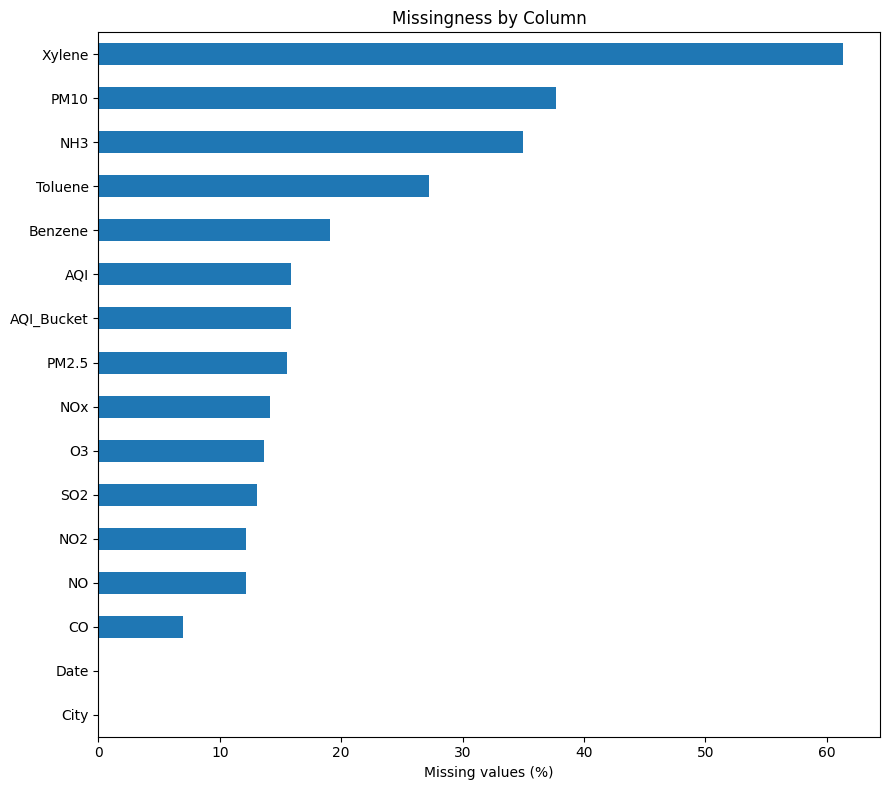

In [7]:

# Percentage of missing values in each column

missing_percent.sort_values().plot(
    kind="barh",
    figsize=(9, 8),
    xlabel="Missing values (%)",
    title="Missingness by Column"
)

plt.tight_layout()
plt.show()


Year,2015,2016,2017,2018,2019,2020
City,,,,,,
Ahmedabad,76.4,34.2,20.0,99.5,98.4,99.5
Aizawl,0.0,0.0,0.0,0.0,0.0,60.7
Amaravati,0.0,0.0,10.4,97.5,87.1,98.4
Amritsar,0.0,0.0,77.5,74.0,99.7,96.2
Bengaluru,78.4,88.8,98.1,94.8,100.0,100.0
Bhopal,0.0,0.0,0.0,0.0,29.0,95.1
Brajrajnagar,0.0,0.0,3.3,69.3,94.5,78.1
Chandigarh,0.0,0.0,0.0,0.0,29.0,100.0
Chennai,77.0,91.8,99.2,100.0,100.0,100.0


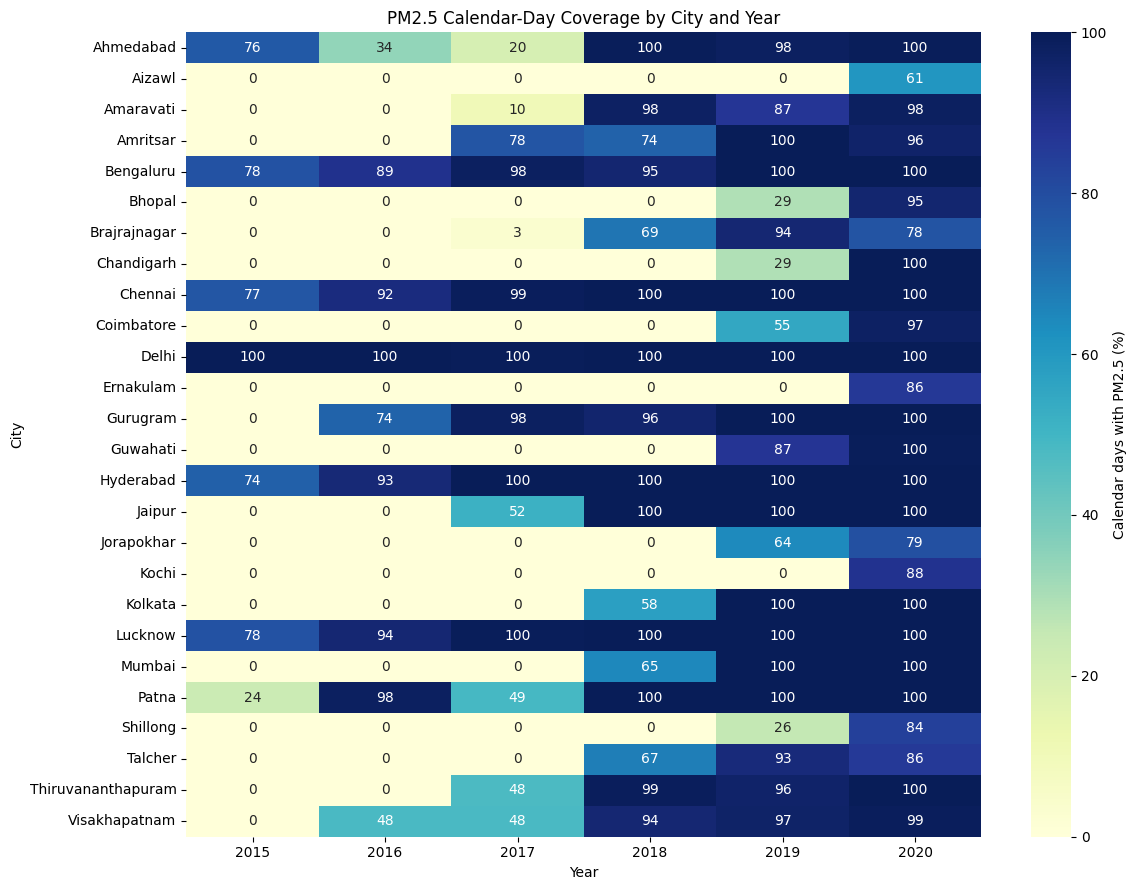

In [8]:

import calendar
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Ensure Date is datetime
df["Date"] = pd.to_datetime(df["Date"])

# Full daily calendar for the overall dataset
all_dates = pd.date_range(
    df["Date"].min(),
    df["Date"].max(),
    freq="D"
)

# Create a complete city-date grid
cities = sorted(df["City"].dropna().unique())

full_index = pd.MultiIndex.from_product(
    [cities, all_dates],
    names=["City", "Date"]
)

# Reindex PM2.5 so dates without rows count as missing
pm25_daily = (
    df.drop_duplicates(["City", "Date"])
      .set_index(["City", "Date"])["PM2.5"]
      .reindex(full_index)
)

coverage_df = pm25_daily.rename("PM2.5").reset_index()
coverage_df["Year"] = coverage_df["Date"].dt.year
coverage_df["available"] = coverage_df["PM2.5"].notna()

# Percentage of calendar days with PM2.5 available
coverage = coverage_df.pivot_table(
    index="City",
    columns="Year",
    values="available",
    aggfunc="mean"
) * 100

coverage = coverage.round(1)
display(coverage)

# Plot and save heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(
    coverage,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Calendar days with PM2.5 (%)"}
)
plt.title("PM2.5 Calendar-Day Coverage by City and Year")
plt.xlabel("Year")
plt.ylabel("City")
plt.tight_layout()

fig_dir = PROJECT_DIR / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    fig_dir / "pm25_coverage_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene
Date,,,,,,,,,,,,
2015,33.7,81.7,15.9,15.9,2.8,57.6,3.1,17.3,16.5,22.4,17.4,52.3
2016,24.0,66.7,23.1,23.0,19.7,61.7,11.8,21.6,24.8,25.2,25.1,63.8
2017,29.8,56.8,26.9,27.0,41.4,55.2,13.0,29.1,29.5,22.1,22.2,62.2
2018,14.6,34.1,9.7,8.9,10.9,30.1,6.6,11.4,11.4,19.8,29.9,62.3
2019,4.2,17.4,2.9,3.6,6.7,20.2,4.6,4.4,3.2,13.5,32.0,63.0
2020,3.6,7.8,4.9,5.0,5.9,11.3,4.0,4.0,7.3,17.1,28.5,59.8


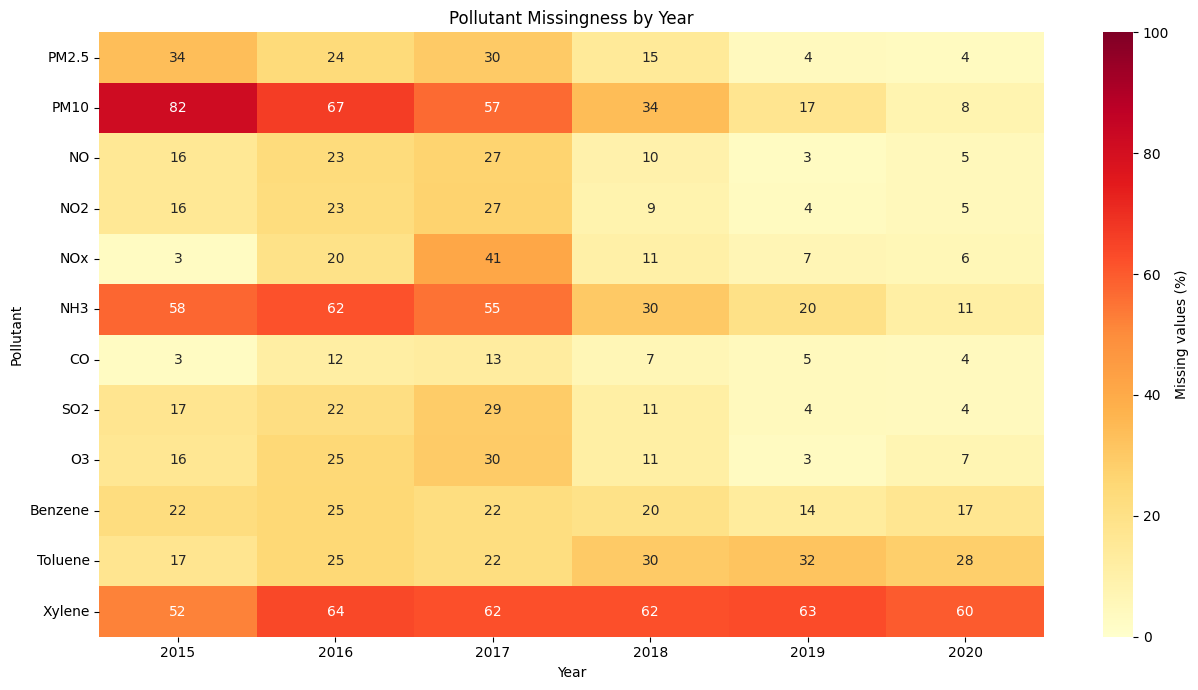

In [9]:

# Day 2: Missingness by pollutant and year

pollutants = [
    col for col in [
        "PM2.5", "PM10", "NO", "NO2", "NOx",
        "NH3", "CO", "SO2", "O3", "Benzene",
        "Toluene", "Xylene"
    ]
    if col in df.columns
]

yearly_missing = (
    df.groupby(df["Date"].dt.year)[pollutants]
      .apply(lambda group: group.isna().mean() * 100)
)

display(yearly_missing.round(1))

plt.figure(figsize=(13, 7))
sns.heatmap(
    yearly_missing.T,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Missing values (%)"}
)

plt.title("Pollutant Missingness by Year")
plt.xlabel("Year")
plt.ylabel("Pollutant")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "pollutant_missingness_by_year.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [10]:

# Find runs of more than 7 consecutive days without PM2.5

gap_records = []

for city in cities:
    city_data = (
        df.loc[df["City"] == city, ["Date", "PM2.5"]]
          .drop_duplicates("Date")
          .set_index("Date")
          .sort_index()
    )

    calendar = pd.date_range(
        city_data.index.min(),
        city_data.index.max(),
        freq="D"
    )

    daily_pm25 = city_data["PM2.5"].reindex(calendar)
    missing = daily_pm25.isna()

    # Give each consecutive run of missing/non-missing days an ID
    run_id = missing.ne(missing.shift()).cumsum()

    for _, run in missing.groupby(run_id):
        if run.iloc[0] and len(run) > 7:
            gap_records.append({
                "City": city,
                "gap_start": run.index[0],
                "gap_end": run.index[-1],
                "gap_days": len(run)
            })

long_gaps = pd.DataFrame(gap_records)

if long_gaps.empty:
    print("No gaps longer than 7 days found.")
else:
    long_gaps = long_gaps.sort_values(
        "gap_days", ascending=False
    )
    display(long_gaps.head(30))


,City,gap_start,gap_end,gap_days
35,Mumbai,2015-01-01,2018-04-25,1211
27,Jorapokhar,2017-04-20,2019-01-08,629
2,Ahmedabad,2016-11-05,2017-10-09,339
1,Ahmedabad,2015-11-09,2016-06-26,231
49,Visakhapatnam,2017-04-12,2017-09-30,172
39,Patna,2017-04-14,2017-09-25,165
37,Patna,2015-06-01,2015-09-30,122
28,Jorapokhar,2019-04-24,2019-08-18,117
25,Hyderabad,2015-01-04,2015-03-30,86
18,Chennai,2015-01-01,2015-03-22,81


### Day 2 — Missingness and Coverage Findings

The dataset has substantial variation in data completeness across pollutants, years, and cities. PM2.5 missingness decreases from 33.7% in 2015 to 3.6% in 2020, while Xylene remains highly incomplete, with approximately 52–64% missingness across the years. Several cities also contain long gaps in PM2.5 observations, particularly Mumbai, Jorapokhar, and Ahmedabad.

These findings indicate that missing-data handling and city selection will be important for reliable next-day forecasting. Missing observations will not be treated as zero, and target values will not be imputed. Feature selection and preprocessing decisions will follow the project specification and use training data only.

In [11]:
# Basic statistics of PM2.5
print("PM2.5 summary statistics:")
display(df["PM2.5"].describe())

# Additional statistics
print("Median:", df["PM2.5"].median())
print("Skewness:", df["PM2.5"].skew())
print("Missing values:", df["PM2.5"].isna().sum())

PM2.5 summary statistics:


,PM2.5
count,24933.000000
mean,67.450578
std,64.661449
min,0.040000
25%,28.820000
50%,48.570000
75%,80.590000
max,949.990000


Median: 48.57
Skewness: 3.3699598508656305
Missing values: 4598


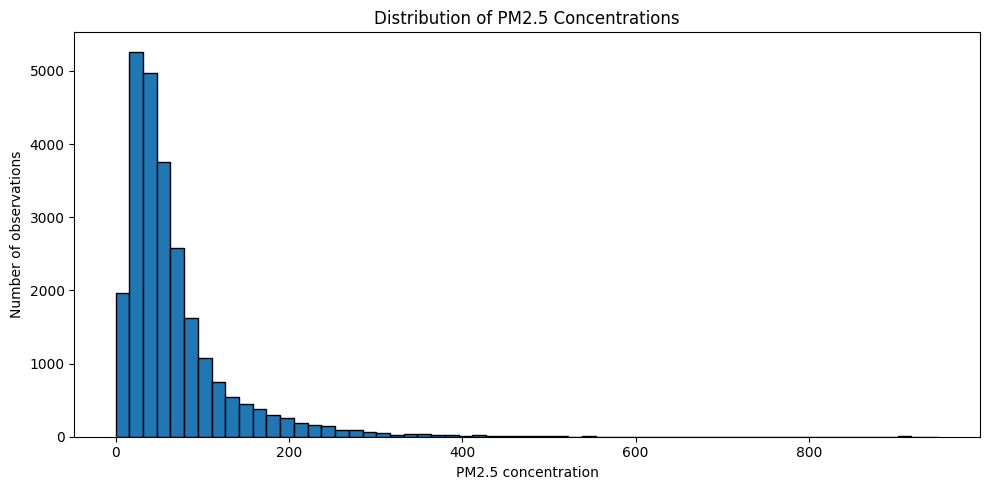

In [12]:
import matplotlib.pyplot as plt

pm25 = df["PM2.5"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(pm25, bins=60, edgecolor="black")
plt.xlabel("PM2.5 concentration")
plt.ylabel("Number of observations")
plt.title("Distribution of PM2.5 Concentrations")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "pm25_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

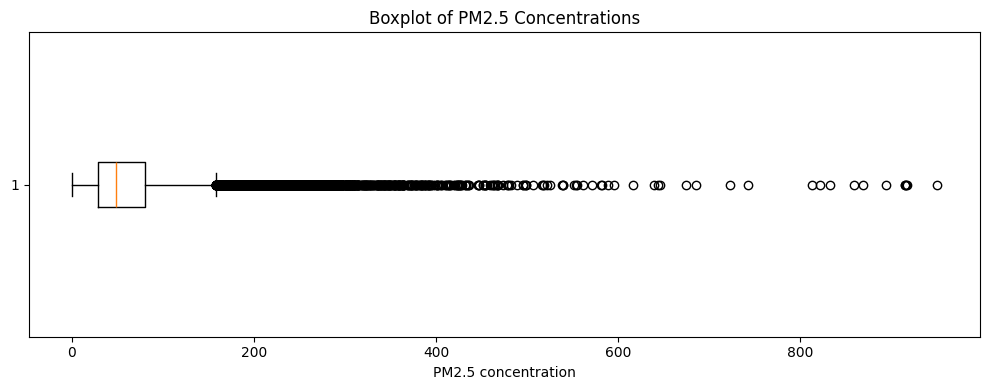

In [13]:
plt.figure(figsize=(10, 4))
plt.boxplot(pm25, vert=False)
plt.xlabel("PM2.5 concentration")
plt.title("Boxplot of PM2.5 Concentrations")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "pm25_boxplot.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Day 3 — PM2.5 Distribution and Outlier Analysis

PM2.5 has a strongly right-skewed distribution, with a mean of 67.45, median of 48.57, and skewness of 3.37. The boxplot shows numerous observations beyond the upper whisker, including some very high concentrations. These are treated as potential outliers rather than automatically classified as errors. They will be retained at this stage because high-pollution episodes may be important for next-day forecasting.

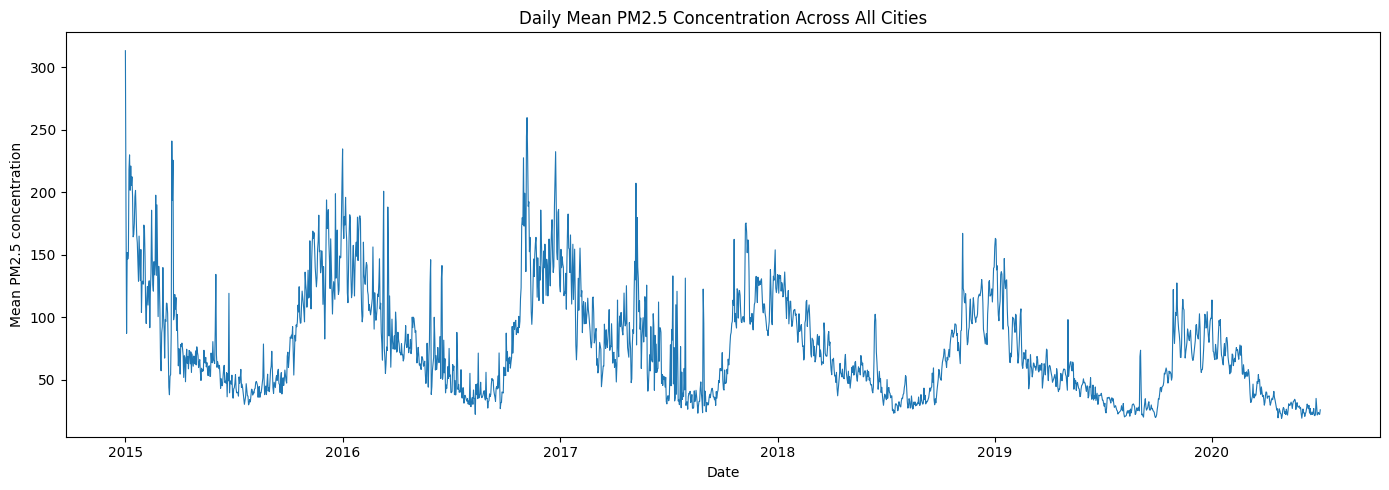

In [14]:
daily_pm25 = (
    df.groupby("Date")["PM2.5"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_pm25.index, daily_pm25.values, linewidth=0.8)
plt.xlabel("Date")
plt.ylabel("Mean PM2.5 concentration")
plt.title("Daily Mean PM2.5 Concentration Across All Cities")
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "figures" / "pm25_temporal_trend.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

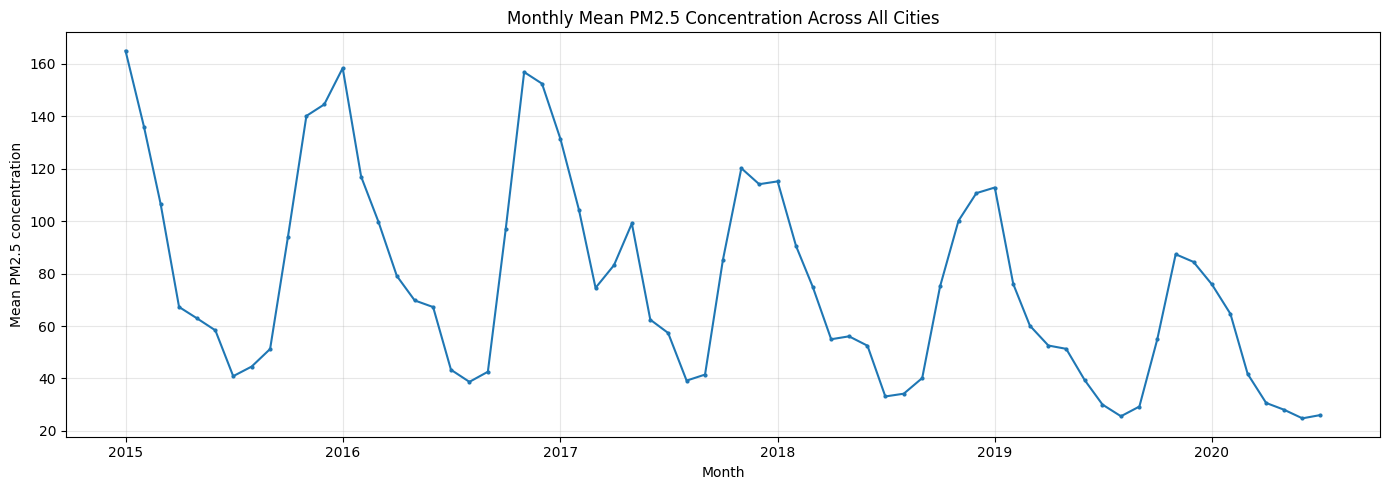

In [15]:
monthly_pm25 = (
    df.groupby(df["Date"].dt.to_period("M"))["PM2.5"]
      .mean()
)

monthly_pm25.index = monthly_pm25.index.to_timestamp()

plt.figure(figsize=(14, 5))
plt.plot(monthly_pm25.index, monthly_pm25.values, marker="o", markersize=2)
plt.xlabel("Month")
plt.ylabel("Mean PM2.5 concentration")
plt.title("Monthly Mean PM2.5 Concentration Across All Cities")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    PROJECT_DIR / "figures" / "pm25_monthly_trend.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Day 3 — Distribution, Outliers, and Temporal Patterns

PM2.5 has a strongly right-skewed distribution, with a mean of 67.45, median of 48.57, and skewness of 3.37. The boxplot identifies numerous potential high-value outliers, which are retained because they may represent genuine high-pollution episodes.

The daily and monthly time-series plots show recurring increases and decreases in average PM2.5 concentrations, suggesting possible annual seasonality. However, these trends are based on available observations across cities, and changing city coverage may influence the pattern. These observations motivate further investigation but do not establish causation or confirm a specific seasonal mechanism.

## Day 4: City Selection and Evaluation Specification

### Objective
Select cities for pooled next-day PM2.5 forecasting and reserve two additional cities for an unseen-city evaluation.

### Selection criteria
The initial rule requires at least 70% PM2.5 coverage across the 2015–2018 training period and at least 70% coverage during the 2019 validation period. Coverage is calculated against the complete calendar, so dates with missing observations or no recorded row count as unavailable.

The selection is based on data coverage and geographic diversity, not model performance. City selection and evaluation dates must be finalized before model training to avoid biased evaluation.

In [16]:
import pandas as pd

# Ensure dates are datetime
df["Date"] = pd.to_datetime(df["Date"])

# Keep one record per city-date for this coverage calculation
daily = df.drop_duplicates(["City", "Date"]).copy()

# Define the project periods
train_dates = pd.date_range("2015-01-01", "2018-12-31", freq="D")
val_dates = pd.date_range("2019-01-01", "2019-12-31", freq="D")

results = []

for city in sorted(daily["City"].dropna().unique()):
    city_data = (
        daily.loc[daily["City"] == city]
        .set_index("Date")["PM2.5"]
    )

    train_coverage = (
        city_data.reindex(train_dates).notna().mean() * 100
    )
    val_coverage = (
        city_data.reindex(val_dates).notna().mean() * 100
    )

    results.append({
        "City": city,
        "Train_coverage_pct": round(train_coverage, 1),
        "Validation_coverage_pct": round(val_coverage, 1),
        "Meets_70pct_rule": (
            train_coverage >= 70 and val_coverage >= 70
        )
    })

city_coverage = pd.DataFrame(results)

city_coverage = city_coverage.sort_values(
    ["Meets_70pct_rule", "Train_coverage_pct"],
    ascending=[False, False]
)

display(city_coverage)

,City,Train_coverage_pct,Validation_coverage_pct,Meets_70pct_rule
10,Delhi,99.9,100.0,True
19,Lucknow,93.0,100.0,True
8,Chennai,92.0,100.0,True
14,Hyderabad,91.9,100.0,True
4,Bengaluru,90.0,100.0,True
21,Patna,67.8,99.7,False
12,Gurugram,66.9,100.0,False
0,Ahmedabad,57.5,98.4,False
25,Visakhapatnam,47.8,96.7,False
3,Amritsar,37.9,99.7,False


### Initial Coverage Assessment

The initial 70% coverage rule identified five qualifying cities: Delhi, Lucknow, Chennai, Hyderabad, and Bengaluru. Patna had 67.8% coverage during 2015–2018 and 99.7% during 2019, placing it just below the training-period threshold.

The project plan permits a one-time fallback when fewer than eight cities qualify: lower the coverage threshold to 60% or use six pooled cities. For this project, I will retain the 70% rule and use the six-city fallback, adding Patna because its training coverage is closest to the threshold among the remaining candidates. This exception and its rationale will be recorded in the frozen specification before model training.

In [17]:
test_dates = pd.date_range(
    "2020-01-01", "2020-07-01", freq="D"
)

pooled_cities = [
    "Delhi", "Lucknow", "Chennai",
    "Hyderabad", "Bengaluru", "Patna"
]

heldout_results = []

for city in sorted(daily["City"].dropna().unique()):
    if city in pooled_cities:
        continue

    city_data = daily.loc[
        daily["City"] == city
    ].set_index("Date")["PM2.5"]

    test_coverage = (
        city_data.reindex(test_dates).notna().mean() * 100
    )

    heldout_results.append({
        "City": city,
        "Test_coverage_pct": round(test_coverage, 1)
    })

heldout_coverage = pd.DataFrame(heldout_results)
display(
    heldout_coverage.sort_values(
        "Test_coverage_pct", ascending=False
    )
)

,City,Test_coverage_pct
15,Mumbai,100.0
11,Jaipur,100.0
9,Gurugram,100.0
6,Chandigarh,100.0
14,Kolkata,100.0
18,Thiruvananthapuram,100.0
10,Guwahati,99.5
0,Ahmedabad,99.5
19,Visakhapatnam,98.9
2,Amaravati,98.4


### Final City Selection

The project uses six pooled cities: Delhi, Lucknow, Chennai, Hyderabad, Bengaluru, and Patna. Five cities met the initial 70% coverage rule in both the training and validation periods. Patna was added as the sixth pooled city using the six-city fallback allowed by the project plan; its training-period coverage is 67.8%, while its 2019 validation coverage is 99.7%.

Mumbai and Guwahati are provisionally selected as held-out cities for unseen-city evaluation. Their PM2.5 coverage from January through July 2020 is 100.0% and 99.5%, respectively. They were selected using test-period coverage and geographic diversity rather than model performance.

The city lists will be frozen before model training. Held-out cities will not be used to train or tune the pooled forecasting models.

# Day 4: Frozen Project Specification

## 1. Project objective

**Title:** Air Quality Forecasting in India: Predicting Next-Day PM2.5 with Machine Learning

The objective is to predict the next day's PM2.5 concentration using information available up to the current day. Each observation represents a city and a date.

## 2. Prediction target

- Target: PM2.5 concentration on the next calendar day.
- Forecast horizon: One day ahead.
- Prediction time: End of the current day.
- No future observations will be used to construct features.
- Missing target values will not be imputed.

## 3. City selection

The initial coverage rule required at least 70% PM2.5 coverage during both 2015–2018 and 2019. Five cities qualified: Delhi, Lucknow, Chennai, Hyderabad, and Bengaluru.

Patna had 67.8% coverage during 2015–2018 and 99.7% during 2019. Because the project plan permits a six-city fallback when too few cities meet the initial rule, Patna is included as the sixth pooled city. This exception is based on coverage, not model performance.

**Pooled cities:**
- Delhi
- Lucknow
- Chennai
- Hyderabad
- Bengaluru
- Patna

**Held-out cities for unseen-city evaluation:**
- Mumbai
- Guwahati

Mumbai and Guwahati were selected based on test-period coverage and geographic diversity, before model training. They will not be used to train or tune the pooled models.

## 4. Time-based data splits

Split membership will be determined by the **target date**, not simply the date on which the input features were recorded.

- Training: target dates in 2015–2018
- Validation: target dates in 2019
- Test: target dates from January through July 2020, limited to dates available in the dataset

The test set will remain untouched during model selection and hyperparameter tuning.

For the 2020 test analysis, results will also be reported separately for the period before 25 March 2020 and the period from 25 March 2020 onward. These are descriptive comparisons, not proof that lockdown caused any observed changes.

## 5. Feature construction and leakage prevention

- Reindex each city's observations to a complete daily calendar before constructing lagged features.
- Construct lagged and rolling features separately within each city.
- Use only current-day and historical information to predict next-day PM2.5.
- Exclude `AQI` and `AQI_Bucket` because they could leak information related to the target.
- Determine high-missingness feature exclusions using training data only.
- Fit imputation, scaling, and categorical encoding using training data only, within a machine-learning pipeline.
- Do not fill missing target values.
- Evaluate models on common eligible observations when comparing errors.

## 6. Baselines and models

Baselines:
1. Persistence: predict tomorrow's PM2.5 using today's PM2.5.
2. Seven-day mean: use the recent seven-day PM2.5 history.

Models to compare:
- Ordinary Least Squares linear regression
- Ridge regression
- Lasso regression
- Support Vector Regression with an RBF kernel
- Random Forest regression
- Histogram-based Gradient Boosting regression

The pooled-city experiment may include city identity as a categorical feature. The unseen-city experiment will use a model configuration that does not depend on city identities learned during training.

## 7. Model selection

- Use time-aware cross-validation within the training period for tuning.
- Use 2019 validation results to compare candidate models and select the final model.
- If a simpler model's MAE is within 2% of the best candidate's MAE, prefer the simpler model.
- Do not use test-set results to choose features, models, or hyperparameters.

## 8. Evaluation metrics

Primary metric:
- Mean Absolute Error (MAE)

Additional metrics:
- Root Mean Squared Error (RMSE)
- Skill relative to persistence: \(1 - \frac{MAE_{\text{model}}}{MAE_{\text{persistence}}}\)

Positive skill indicates improvement over the persistence baseline.

## 9. Reproducibility and reporting

- Random seed: 42 wherever applicable.
- Record feature exclusions and preprocessing decisions.
- Save plots, metrics, and model comparisons in the project outputs.
- Report limitations caused by missing observations and uneven city coverage.
- Describe predictive relationships as associations, not proof of causation.
- Refit the selected configuration using training plus validation data before evaluating the test set once, on Day 13.


## Day 5: Next-Day Target and Feature Engineering

### Objective

Create a forecasting dataset in which each row contains information available at the end of a given day and the PM2.5 concentration on the following day.

### Planned features

- Current-day PM2.5
- PM2.5 lagged by 1, 2, 3, and 7 days
- Rolling averages of recent PM2.5 observations
- Historical pollutant measurements, where appropriate
- City identity for pooled-city modelling

### Leakage prevention

All lagged and rolling features will be calculated separately for each city after reindexing to a complete daily calendar. The next-day target will be created using the following calendar day's PM2.5 value.

Missing target values will not be imputed. Rows with unavailable required inputs will be handled according to the project specification and model pipeline.

No models will be trained during this step.


In [18]:
import pandas as pd
import numpy as np

# Work on a copy; keep the original dataframe unchanged
data = df.copy()

# Convert Date to datetime
data["Date"] = pd.to_datetime(data["Date"])

# Keep only the six pooled cities
pooled_cities = [
    "Delhi", "Lucknow", "Chennai",
    "Hyderabad", "Bengaluru", "Patna"
]

data = data[data["City"].isin(pooled_cities)].copy()

# Sort observations by city and date
data = data.sort_values(["City", "Date"])

# Check for duplicate city-date observations
print("Duplicate city-date rows:", data.duplicated(["City", "Date"]).sum())

# Display the selected data
print("Shape:", data.shape)
print("Cities:", sorted(data["City"].unique()))
display(data[["City", "Date", "PM2.5"]].head())

Duplicate city-date rows: 0
Shape: (11900, 16)
Cities: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Lucknow', 'Patna']


,City,Date,PM2.5
4294,Bengaluru,2015-01-01,NaN
4295,Bengaluru,2015-01-02,NaN
4296,Bengaluru,2015-01-03,NaN
4297,Bengaluru,2015-01-04,NaN
4298,Bengaluru,2015-01-05,NaN


### Step 2: Create a Complete Daily Calendar

The original dataset may contain missing dates for individual cities. I will reindex each city to a continuous daily calendar so that missing dates are explicitly represented by missing values.

This ensures that lagged features correspond to actual calendar days. Missing PM2.5 observations will remain missing rather than being filled artificially.


In [19]:
# Create a complete daily calendar separately for each city
daily_data = []

for city in pooled_cities:
    city_data = data[data["City"] == city].copy()

    # Use the full date range covered by the original dataset
    calendar = pd.date_range(
        start=data["Date"].min(),
        end=data["Date"].max(),
        freq="D"
    )

    # Set Date as index and add missing calendar dates
    city_data = city_data.set_index("Date")
    city_data = city_data.reindex(calendar)

    # Restore the date and city columns
    city_data.index.name = "Date"
    city_data = city_data.reset_index()
    city_data["City"] = city

    daily_data.append(city_data)

# Combine all cities
daily_df = pd.concat(daily_data, ignore_index=True)

# Sort by city and date
daily_df = daily_df.sort_values(["City", "Date"]).reset_index(drop=True)

print("Shape after reindexing:", daily_df.shape)
print("\nMissing PM2.5 values after reindexing:")
print(daily_df["PM2.5"].isna().sum())

print("\nRows per city:")
print(daily_df.groupby("City").size())

display(daily_df[["City", "Date", "PM2.5"]].head(10))

Shape after reindexing: (12054, 16)

Missing PM2.5 values after reindexing:
957

Rows per city:
City
Bengaluru    2009
Chennai      2009
Delhi        2009
Hyderabad    2009
Lucknow      2009
Patna        2009
dtype: int64


,City,Date,PM2.5
0,Bengaluru,2015-01-01,NaN
1,Bengaluru,2015-01-02,NaN
2,Bengaluru,2015-01-03,NaN
3,Bengaluru,2015-01-04,NaN
4,Bengaluru,2015-01-05,NaN
5,Bengaluru,2015-01-06,NaN
6,Bengaluru,2015-01-07,NaN
7,Bengaluru,2015-01-08,NaN
8,Bengaluru,2015-01-09,NaN
9,Bengaluru,2015-01-10,NaN


### Step 3: Create the Next-Day PM2.5 Target

The target variable will be the PM2.5 concentration on the next calendar day.

Within each city, I will shift the PM2.5 column by one row in the negative direction. Because the data has already been sorted and reindexed to a complete daily calendar, this corresponds to the next calendar day.

The target date will also be stored explicitly to support the time-based train, validation, and test splits.

Missing target values will remain missing and will not be imputed.


In [20]:
# Ensure chronological order within each city
daily_df = daily_df.sort_values(
    ["City", "Date"]
).reset_index(drop=True)

# Target date = next calendar day
daily_df["Target_Date"] = (
    daily_df.groupby("City")["Date"].shift(-1)
)

# Target = next day's PM2.5
daily_df["PM2.5_next_day"] = (
    daily_df.groupby("City")["PM2.5"].shift(-1)
)

# Inspect one city to verify the shift
display(
    daily_df.loc[
        daily_df["City"] == "Delhi",
        ["City", "Date", "PM2.5", "Target_Date", "PM2.5_next_day"]
    ].head(15)
)

print(
    "\nMissing next-day targets:",
    daily_df["PM2.5_next_day"].isna().sum()
)

,City,Date,PM2.5,Target_Date,PM2.5_next_day
4018,Delhi,2015-01-01,313.22,2015-01-02,186.18
4019,Delhi,2015-01-02,186.18,2015-01-03,87.18
4020,Delhi,2015-01-03,87.18,2015-01-04,151.84
4021,Delhi,2015-01-04,151.84,2015-01-05,146.60
4022,Delhi,2015-01-05,146.60,2015-01-06,149.58
4023,Delhi,2015-01-06,149.58,2015-01-07,217.87
4024,Delhi,2015-01-07,217.87,2015-01-08,229.90
4025,Delhi,2015-01-08,229.90,2015-01-09,201.66
4026,Delhi,2015-01-09,201.66,2015-01-10,221.02
4027,Delhi,2015-01-10,221.02,2015-01-11,205.41



Missing next-day targets: 958


### Step 4: Create Historical PM2.5 Features

I will construct lagged PM2.5 features and rolling averages separately for each city. Lagged features will represent specific calendar days, while rolling averages will summarize recent PM2.5 levels.

Rolling averages will require all observations in their respective windows to be available. Missing historical values will remain missing rather than being filled with zero.

All features will use information available on the feature date or earlier, preventing future-data leakage.


In [21]:
# Sort before constructing time-dependent features
daily_df = daily_df.sort_values(
    ["City", "Date"]
).reset_index(drop=True)

# Lagged PM2.5 features
for lag in [1, 2, 3, 7]:
    daily_df[f"PM2.5_lag_{lag}"] = (
        daily_df.groupby("City")["PM2.5"].shift(lag)
    )

# Rolling averages, calculated separately for each city
daily_df["PM2.5_roll_mean_3"] = (
    daily_df.groupby("City")["PM2.5"]
    .transform(lambda s: s.rolling(window=3, min_periods=3).mean())
)

daily_df["PM2.5_roll_mean_7"] = (
    daily_df.groupby("City")["PM2.5"]
    .transform(lambda s: s.rolling(window=7, min_periods=7).mean())
)

# Inspect the generated features for Delhi
feature_cols = [
    "City", "Date", "PM2.5",
    "PM2.5_lag_1", "PM2.5_lag_2",
    "PM2.5_lag_3", "PM2.5_lag_7",
    "PM2.5_roll_mean_3", "PM2.5_roll_mean_7",
    "Target_Date", "PM2.5_next_day"
]

display(
    daily_df.loc[
        daily_df["City"] == "Delhi",
        feature_cols
    ].head(12)
)

,City,Date,PM2.5,PM2.5_lag_1,PM2.5_lag_2,PM2.5_lag_3,PM2.5_lag_7,PM2.5_roll_mean_3,PM2.5_roll_mean_7,Target_Date,PM2.5_next_day
4018,Delhi,2015-01-01,313.22,NaN,NaN,NaN,NaN,NaN,NaN,2015-01-02,186.18
4019,Delhi,2015-01-02,186.18,313.22,NaN,NaN,NaN,NaN,NaN,2015-01-03,87.18
4020,Delhi,2015-01-03,87.18,186.18,313.22,NaN,NaN,195.526667,NaN,2015-01-04,151.84
4021,Delhi,2015-01-04,151.84,87.18,186.18,313.22,NaN,141.733333,NaN,2015-01-05,146.60
4022,Delhi,2015-01-05,146.60,151.84,87.18,186.18,NaN,128.540000,NaN,2015-01-06,149.58
4023,Delhi,2015-01-06,149.58,146.60,151.84,87.18,NaN,149.340000,NaN,2015-01-07,217.87
4024,Delhi,2015-01-07,217.87,149.58,146.60,151.84,NaN,171.350000,178.924286,2015-01-08,229.90
4025,Delhi,2015-01-08,229.90,217.87,149.58,146.60,313.22,199.116667,167.021429,2015-01-09,201.66
4026,Delhi,2015-01-09,201.66,229.90,217.87,149.58,186.18,216.476667,169.232857,2015-01-10,221.02
4027,Delhi,2015-01-10,221.02,201.66,229.90,217.87,87.18,217.526667,188.352857,2015-01-11,205.41


### Step 5: Add Current-Day Pollutant Features

Current-day measurements of other pollutants will be considered as candidate predictors of next-day PM2.5. These measurements are available at the forecast time in the intended prediction setup.

AQI and AQI_Bucket will be excluded. Missing predictor values will be handled later through a preprocessing pipeline fitted on training data only.

Feature selection and missingness-based exclusions will be determined without examining test-set outcomes.


In [22]:
print("Dataset shape:", daily_df.shape)

print("\nColumns containing pollutant names:")
print([
    col for col in daily_df.columns
    if any(
        pollutant.lower() in col.lower()
        for pollutant in [
            "PM10", "NO", "NO2", "NOx", "NH3",
            "CO", "SO2", "O3", "Benzene",
            "Toluene", "Xylene"
        ]
    )
])

Dataset shape: (12054, 24)

Columns containing pollutant names:
['PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']


In [23]:
# Remove the pollutant columns from the original reindexed dataframe
# by dropping the duplicate suffixed versions, then rename the _y columns.

pollutant_cols = [
    "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]

# Keep the columns that came from the merge
daily_df = daily_df.drop(
    columns=[f"{col}_x" for col in pollutant_cols
             if f"{col}_x" in daily_df.columns]
)

# Restore the original pollutant column names
daily_df = daily_df.rename(
    columns={f"{col}_y": col for col in pollutant_cols
             if f"{col}_y" in daily_df.columns}
)

print("Dataset shape:", daily_df.shape)
print("\nPollutant columns:")
print([col for col in pollutant_cols if col in daily_df.columns])

display(
    daily_df[
        ["City", "Date", "PM2.5"] + pollutant_cols
    ].head(10)
)

Dataset shape: (12054, 24)

Pollutant columns:
['PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene
0,Bengaluru,2015-01-01,NaN,NaN,3.26,17.33,10.88,20.36,0.33,3.54,10.73,0.56,4.64,NaN
1,Bengaluru,2015-01-02,NaN,NaN,6.05,19.73,14.14,23.74,1.35,3.97,22.77,0.65,5.31,NaN
2,Bengaluru,2015-01-03,NaN,NaN,11.91,19.88,20.72,4.32,17.40,13.61,12.03,0.53,19.25,NaN
3,Bengaluru,2015-01-04,NaN,NaN,7.45,21.61,16.88,0.87,5.05,6.52,17.70,0.55,7.47,NaN
4,Bengaluru,2015-01-05,NaN,NaN,9.52,22.17,21.76,31.38,1.83,4.71,12.72,0.40,4.36,NaN
5,Bengaluru,2015-01-06,NaN,NaN,6.60,23.20,16.24,26.35,0.52,4.42,13.82,22.68,4.11,NaN
6,Bengaluru,2015-01-07,NaN,NaN,22.60,28.66,30.84,22.73,1.46,5.13,16.98,34.66,8.65,NaN
7,Bengaluru,2015-01-08,NaN,NaN,7.50,31.10,21.16,38.67,2.30,7.07,17.35,31.00,8.60,NaN
8,Bengaluru,2015-01-09,NaN,NaN,6.75,25.98,15.03,23.48,0.54,12.84,16.27,30.51,8.44,NaN
9,Bengaluru,2015-01-10,NaN,NaN,3.38,29.23,16.76,34.17,1.69,3.08,25.01,36.42,13.41,NaN


### Step 6: Assess Missingness in Candidate Predictors

Before finalizing the feature set, I will calculate the percentage of missing values in each candidate predictor across the selected cities and time periods.

This is an initial diagnostic only. The final rule for excluding predictors with high missingness will be applied using the training period only, to avoid using validation or test data to make preprocessing decisions.

Missing target values will not be imputed.


In [24]:
# Candidate predictors: PM2.5 history and current-day pollutants
candidate_features = [
    "PM2.5",
    "PM2.5_lag_1",
    "PM2.5_lag_2",
    "PM2.5_lag_3",
    "PM2.5_lag_7",
    "PM2.5_roll_mean_3",
    "PM2.5_roll_mean_7",
] + pollutant_cols

# Calculate missingness for an initial overview
missing_summary = pd.DataFrame({
    "Missing_count": daily_df[candidate_features].isna().sum(),
    "Missing_pct": daily_df[candidate_features].isna().mean() * 100
}).sort_values("Missing_pct", ascending=False)

display(missing_summary.round(2))

print("\nTarget missing percentage:")
print(
    round(daily_df["PM2.5_next_day"].isna().mean() * 100, 2),
    "%"
)

,Missing_count,Missing_pct
Xylene,7261,60.24
PM10,6329,52.51
NH3,3859,32.01
PM2.5_roll_mean_7,1277,10.59
Benzene,1103,9.15
PM2.5_roll_mean_3,1072,8.89
PM2.5_lag_7,999,8.29
PM2.5_lag_3,975,8.09
PM2.5_lag_2,969,8.04
PM2.5_lag_1,963,7.99



Target missing percentage:
7.95 %


### Step 7: Training-Only Missingness Assessment

I will calculate predictor missingness using only observations whose target dates fall within the training period, 2015–2018.

Predictors with more than 40% missing values in this training subset will be excluded from the candidate feature set. Validation and test data will not be used to make this decision.

This keeps feature selection separate from the later evaluation periods and reduces the risk of information leakage.


In [25]:
# Define the training period using the target date
train_mask = (
    (daily_df["Target_Date"] >= "2015-01-01") &
    (daily_df["Target_Date"] <= "2018-12-31")
)

train_data_for_missingness = daily_df.loc[train_mask].copy()

# Candidate features
candidate_features = [
    "PM2.5",
    "PM2.5_lag_1",
    "PM2.5_lag_2",
    "PM2.5_lag_3",
    "PM2.5_lag_7",
    "PM2.5_roll_mean_3",
    "PM2.5_roll_mean_7",
] + pollutant_cols

# Calculate training-only missingness
train_missing_summary = pd.DataFrame({
    "Missing_count": train_data_for_missingness[candidate_features].isna().sum(),
    "Missing_pct": (
        train_data_for_missingness[candidate_features].isna().mean() * 100
    )
}).sort_values("Missing_pct", ascending=False)

display(train_missing_summary.round(2))

# Exclude features with more than 40% missingness
excluded_features = train_missing_summary.loc[
    train_missing_summary["Missing_pct"] > 40
].index.tolist()

selected_features = [
    col for col in candidate_features
    if col not in excluded_features
]

print("Excluded features:", excluded_features)
print("Selected features:", selected_features)

,Missing_count,Missing_pct
Xylene,5598,63.90
PM10,5175,59.08
NH3,3485,39.78
PM2.5_roll_mean_7,1270,14.50
Benzene,1087,12.41
PM2.5_roll_mean_3,1069,12.20
PM2.5_lag_7,998,11.39
PM2.5_lag_3,974,11.12
PM2.5_lag_2,968,11.05
PM2.5_lag_1,962,10.98


Excluded features: ['Xylene', 'PM10']
Selected features: ['PM2.5', 'PM2.5_lag_1', 'PM2.5_lag_2', 'PM2.5_lag_3', 'PM2.5_lag_7', 'PM2.5_roll_mean_3', 'PM2.5_roll_mean_7', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']


### Step 8: Freeze the Candidate Feature Set

Using only rows whose target dates fall in 2015–2018, I applied the predefined rule of excluding candidate predictors with more than 40% missing values.

The excluded predictors are Xylene (63.90% missing) and PM10 (59.08% missing). NH3 is retained because its training-period missingness is 39.78%, below the exclusion threshold.

The remaining 16 candidate predictors will be used for subsequent modelling experiments. Missing predictor values will be handled within preprocessing pipelines fitted on training data only. The next-day PM2.5 target will never be imputed.


In [26]:
# Confirm the selected and excluded features
print("Number of candidate features:", len(candidate_features))
print("Number of excluded features:", len(excluded_features))
print("Number of selected features:", len(selected_features))

assert len(excluded_features) == 2
assert "Xylene" in excluded_features
assert "PM10" in excluded_features
assert "NH3" in selected_features
assert "AQI" not in selected_features
assert "AQI_Bucket" not in selected_features

print("\nFeature-selection checks passed.")

Number of candidate features: 18
Number of excluded features: 2
Number of selected features: 16

Feature-selection checks passed.


### Step 9: Save the Prepared Forecasting Dataset

I will save the prepared six-city dataset, including the next-day target, historical PM2.5 features, and candidate pollutant predictors.

The dataset will retain missing values so that missingness remains transparent. The raw dataset will remain unchanged, and the prepared data will be stored privately in Google Drive rather than uploaded to GitHub.


In [27]:
from pathlib import Path

# Create an output folder if it does not exist
OUTPUT_DIR = Path(PROJECT_DIR) / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the prepared dataset
prepared_path = OUTPUT_DIR / "prepared_city_daily.csv"
daily_df.to_csv(prepared_path, index=False)

print("Saved to:", prepared_path)
print("Dataset shape:", daily_df.shape)
print("File exists:", prepared_path.exists())

Saved to: /content/drive/MyDrive/PM25_project/outputs/prepared_city_daily.csv
Dataset shape: (12054, 24)
File exists: True


### Step 10: Define Time-Based Data Splits

The forecasting dataset will be split chronologically using the target date. Training observations will have target dates in 2015–2018, validation observations in 2019, and test observations from January through July 2020.

This approach prevents future target observations from entering the training period. The test set will remain untouched until the final evaluation stage.


In [28]:
# Assign a split based on the target date
daily_df["Split"] = np.select(
    [
        daily_df["Target_Date"].between(
            pd.Timestamp("2015-01-01"),
            pd.Timestamp("2018-12-31")
        ),
        daily_df["Target_Date"].between(
            pd.Timestamp("2019-01-01"),
            pd.Timestamp("2019-12-31")
        ),
        daily_df["Target_Date"].between(
            pd.Timestamp("2020-01-01"),
            pd.Timestamp("2020-07-01")
        )
    ],
    ["train", "validation", "test"],
    default="outside"
)

# Check the number of rows assigned to each period
print("Rows per split:")
print(daily_df["Split"].value_counts())

print("\nUnique target dates per split:")
print(daily_df.groupby("Split")["Target_Date"].agg(["min", "max"]))

print("\nRows per city and split:")
display(pd.crosstab(daily_df["City"], daily_df["Split"]))

Rows per split:
Split
train         8760
validation    2190
test          1098
outside          6
Name: count, dtype: int64

Unique target dates per split:
                  min        max
Split                           
outside           NaT        NaT
test       2020-01-01 2020-07-01
train      2015-01-02 2018-12-31
validation 2019-01-01 2019-12-31

Rows per city and split:


Split,outside,test,train,validation
City,,,,
Bengaluru,1,183,1460,365
Chennai,1,183,1460,365
Delhi,1,183,1460,365
Hyderabad,1,183,1460,365
Lucknow,1,183,1460,365
Patna,1,183,1460,365


### Step 11: Save the Dataset with Time-Based Splits

I will save the prepared dataset again after adding the chronological split labels. This preserves the training, validation, and test assignments for later experiments. The final six rows without a next-day target will remain in the saved dataset for transparency and will be excluded when preparing model-evaluation data.

In [29]:
# Save the dataset again, now including the Split column
prepared_path = OUTPUT_DIR / "prepared_city_daily.csv"
daily_df.to_csv(prepared_path, index=False)

# Verify the saved dataset
saved_df = pd.read_csv(prepared_path)

print("Saved successfully:", prepared_path.exists())
print("Saved dataset shape:", saved_df.shape)
print("Split column exists:", "Split" in saved_df.columns)
print("\nSaved split counts:")
print(saved_df["Split"].value_counts())

Saved successfully: True
Saved dataset shape: (12054, 25)
Split column exists: True

Saved split counts:
Split
train         8760
validation    2190
test          1098
outside          6
Name: count, dtype: int64


### Step 11: Verify Time Splits and Forecasting Eligibility

Before modelling, I will verify that the chronological splits are correct and identify observations with both a current-day PM2.5 measurement and a next-day PM2.5 target.

The target date determines the split: training covers 2015–2018, validation covers 2019, and testing covers January–July 2020. Rows without a valid next-day target will not be used for supervised model evaluation.

The test period will remain untouched during feature development and model selection.

In [30]:

# 1. Verify the target and split columns
print("Target_Date dtype:", daily_df["Target_Date"].dtype)
print("\nSplit counts:")
print(daily_df["Split"].value_counts())

# 2. Check that every labelled row belongs to the correct period
train_ok = daily_df.loc[daily_df["Split"] == "train", "Target_Date"].between(
    "2015-01-01", "2018-12-31"
).all()

val_ok = daily_df.loc[daily_df["Split"] == "validation", "Target_Date"].between(
    "2019-01-01", "2019-12-31"
).all()

test_ok = daily_df.loc[daily_df["Split"] == "test", "Target_Date"].between(
    "2020-01-01", "2020-07-01"
).all()

print("\nSplit checks:")
print("Training dates correct:", train_ok)
print("Validation dates correct:", val_ok)
print("Test dates correctly labelled:", test_ok)

# 3. Count rows with a valid current-day and next-day PM2.5 value
eligible = (
    daily_df["PM2.5"].notna()
    & daily_df["PM2.5_next_day"].notna()
    & daily_df["Target_Date"].notna()
    & daily_df["Split"].isin(["train", "validation", "test"])
)

print("\nEligible rows by split:")
print(daily_df.loc[eligible, "Split"].value_counts().reindex(
    ["train", "validation", "test"], fill_value=0
))

# 4. Check missing targets and final rows for each city
print("\nRows without a next-day target:", daily_df["PM2.5_next_day"].isna().sum())

display(
    daily_df.loc[
        daily_df["Target_Date"].isna(),
        ["City", "Date", "Target_Date", "PM2.5", "PM2.5_next_day", "Split"]
    ]
)


Target_Date dtype: datetime64[ns]

Split counts:
Split
train         8760
validation    2190
test          1098
outside          6
Name: count, dtype: int64

Split checks:
Training dates correct: True
Validation dates correct: True
Test dates correctly labelled: True

Eligible rows by split:
Split
train         7751
validation    2188
test          1098
Name: count, dtype: int64

Rows without a next-day target: 958


,City,Date,Target_Date,PM2.5,PM2.5_next_day,Split
2008,Bengaluru,2020-07-01,NaT,17.50,NaN,outside
4017,Chennai,2020-07-01,NaT,15.95,NaN,outside
6026,Delhi,2020-07-01,NaT,54.01,NaN,outside
8035,Hyderabad,2020-07-01,NaT,26.83,NaN,outside
10044,Lucknow,2020-07-01,NaT,34.97,NaN,outside
12053,Patna,2020-07-01,NaT,35.42,NaN,outside


### Step 12: Check Baseline Availability

I will check the availability of the persistence and seven-day mean baselines across the chronological splits. The persistence baseline requires a valid current-day PM2.5 value, while the seven-day mean baseline requires a valid rolling mean.

I will retain observed target values only and will not impute missing targets. These checks will help establish a fair evaluation procedure for comparing the forecasting models.

In [31]:

# Check baseline availability without calculating model performance
valid_target = daily_df["PM2.5_next_day"].notna()

persistence_available = (
    valid_target
    & daily_df["PM2.5"].notna()
)

mean7_available = (
    valid_target
    & daily_df["PM2.5_roll_mean_7"].notna()
)

baseline_check = pd.DataFrame({
    "eligible_target_rows": (
        valid_target
        & daily_df["Split"].isin(["train", "validation", "test"])
    ),
    "persistence_available": persistence_available,
    "7_day_mean_available": mean7_available
})

print("Baseline availability by split:")
display(
    baseline_check.loc[
        daily_df["Split"].isin(["train", "validation", "test"])
    ].groupby(daily_df["Split"]).sum().astype(int)
)

print("\nRows eligible for both baselines, by split:")
common_baseline_rows = (
    persistence_available
    & mean7_available
    & daily_df["Split"].isin(["train", "validation", "test"])
)

print(
    daily_df.loc[common_baseline_rows, "Split"]
    .value_counts()
    .reindex(["train", "validation", "test"], fill_value=0)
)


Baseline availability by split:


,eligible_target_rows,persistence_available,7_day_mean_available
Split,,,
test,1098,1098,1098
train,7809,7751,7448
validation,2189,2188,2182



Rows eligible for both baselines, by split:
Split
train         7448
validation    2182
test          1098
Name: count, dtype: int64


### Step 13: Prepare the Modelling Table

I will create a modelling table containing the selected predictor features, next-day PM2.5 target, city, date, target date, and chronological split label.

Missing predictor values will be retained for appropriate preprocessing within the modelling pipeline. Rows without an observed target or current-day PM2.5 value will not be used for forecasting evaluation. A separate eligibility flag will identify rows where both baseline methods can produce predictions.

The test period will remain reserved for final evaluation.

In [32]:

# Keep rows with a valid target and current-day PM2.5.
# Missing values in other predictors are intentionally retained.
model_df = daily_df.loc[
    daily_df["Split"].isin(["train", "validation", "test"])
    & daily_df["PM2.5"].notna()
    & daily_df["PM2.5_next_day"].notna()
].copy()

# Flag rows where both baselines can produce predictions
model_df["baseline_comparable"] = (
    model_df["PM2.5_roll_mean_7"].notna()
)

# Keep only the metadata, target, selected features, and baseline flag
metadata_cols = ["City", "Date", "Target_Date", "Split"]
target_col = ["PM2.5_next_day"]

model_df = model_df[
    metadata_cols + selected_features + target_col + ["baseline_comparable"]
]

print("Modelling table shape:", model_df.shape)

print("\nRows per split:")
print(model_df["Split"].value_counts())

print("\nBaseline-comparable rows per split:")
print(
    model_df.groupby("Split")["baseline_comparable"]
    .sum()
    .astype(int)
)

print("\nSelected features:")
print(selected_features)

print("\nTarget missing:", model_df["PM2.5_next_day"].isna().sum())
print("Current PM2.5 missing:", model_df["PM2.5"].isna().sum())
print("Duplicate city-target-date rows:",
      model_df.duplicated(["City", "Target_Date"]).sum())


Modelling table shape: (11037, 22)

Rows per split:
Split
train         7751
validation    2188
test          1098
Name: count, dtype: int64

Baseline-comparable rows per split:
Split
test          1098
train         7448
validation    2182
Name: baseline_comparable, dtype: int64

Selected features:
['PM2.5', 'PM2.5_lag_1', 'PM2.5_lag_2', 'PM2.5_lag_3', 'PM2.5_lag_7', 'PM2.5_roll_mean_3', 'PM2.5_roll_mean_7', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']

Target missing: 0
Current PM2.5 missing: 0
Duplicate city-target-date rows: 0


### Step 14: Save the Modelling Table

The modelling table has passed the initial data-quality checks. I will save it as a separate prepared file, preserving the chronological split labels and baseline-eligibility flag.

The original raw dataset and the earlier prepared dataset will remain unchanged. The saved table will be used in subsequent modelling stages, with preprocessing fitted only on the training data.

In [33]:

from pathlib import Path

OUTPUT_DIR = Path(PROJECT_DIR) / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "model_ready_dataset.csv"
model_df.to_csv(model_path, index=False)

# Verify the saved file
saved_model_df = pd.read_csv(model_path)

print("Saved successfully:", model_path.exists())
print("Saved shape:", saved_model_df.shape)
print("Split counts:")
print(saved_model_df["Split"].value_counts())
print("Missing targets:", saved_model_df["PM2.5_next_day"].isna().sum())
print("Duplicate city-target-date rows:",
      saved_model_df.duplicated(["City", "Target_Date"]).sum())


Saved successfully: True
Saved shape: (11037, 22)
Split counts:
Split
train         7751
validation    2188
test          1098
Name: count, dtype: int64
Missing targets: 0
Duplicate city-target-date rows: 0


## Weekly Experiment Log — Week 1

### Work completed
- Inspected PM2.5 distribution, missingness, and temporal patterns.
- Selected six pooled cities: Bengaluru, Chennai, Delhi, Hyderabad, Lucknow, and Patna.
- Selected Mumbai and Guwahati as held-out cities for the planned unseen-city analysis.
- Reindexed each pooled city to a continuous daily calendar.
- Created the next-day PM2.5 target, historical PM2.5 lags, rolling means, and candidate pollutant predictors.
- Excluded Xylene and PM10 because their training-period missingness exceeded 40%.
- Created chronological training (2015–2018), validation (2019), and test (January–July 2020) splits.
- Saved the prepared modelling table to Google Drive.

### Data checks
- Prepared modelling table: 11,037 rows and 22 columns.
- Training: 7,751 rows.
- Validation: 2,188 rows.
- Test: 1,098 rows.
- Missing next-day targets in the modelling table: 0.
- Duplicate city–target-date rows: 0.

### Decisions and limitations
- Missing target values were not imputed.
- Missing predictor values are retained for appropriate preprocessing.
- Test performance has not been evaluated.
- Observed temporal patterns are descriptive and do not establish causation.

### Next steps
- Begin baseline and model-development preparation according to the project plan.
- Fit preprocessing using training data only.
- Use validation data for model selection.
- Reserve the test set for final evaluation.

In [34]:

from pathlib import Path

log_path = Path(PROJECT_DIR) / "outputs" / "weekly_experiment_log.md"

weekly_entry = """
# Weekly Experiment Log — Week 1

## Work completed
- Inspected PM2.5 distribution, missingness, and temporal patterns.
- Selected six pooled cities: Bengaluru, Chennai, Delhi, Hyderabad, Lucknow, and Patna.
- Selected Mumbai and Guwahati for the planned held-out-city analysis.
- Created daily calendars, next-day targets, lag features, and rolling means.
- Excluded Xylene and PM10 using the training-only missingness threshold.
- Created chronological training, validation, and test splits.
- Saved the modelling table to Google Drive.

## Data checks
- Modelling table: 11,037 rows and 22 columns.
- Training: 7,751 rows; validation: 2,188 rows; test: 1,098 rows.
- Missing next-day targets: 0.
- Duplicate city-target-date rows: 0.

## Decisions and limitations
- Missing targets were not imputed.
- Missing predictors are retained for later preprocessing.
- Test performance has not been evaluated.
- Descriptive patterns do not establish causation.

## Next steps
- Continue baseline and model-development preparation.
- Fit preprocessing on training data only.
- Select models using validation data.
- Reserve the test set for final evaluation.
"""

log_path.parent.mkdir(parents=True, exist_ok=True)

with log_path.open("a", encoding="utf-8") as f:
    f.write("\n" + weekly_entry.strip() + "\n")

print("Weekly log saved:", log_path)
print("File exists:", log_path.exists())


Weekly log saved: /content/drive/MyDrive/PM25_project/outputs/weekly_experiment_log.md
File exists: True
